In [1]:
# Cell 1: Mount Google Drive and set up persistent directories
from google.colab import drive
import os

drive.mount('/content/drive')

# Create persistent storage folder on Google Drive
DRIVE_DIR = "/content/drive/MyDrive/TreeSense_AI_Training_main"
DATASET_DIR = os.path.join(DRIVE_DIR, "dataset")
CHECKPOINT_DIR = os.path.join(DRIVE_DIR, "checkpoints")
EXPORTS_DIR = os.path.join(DRIVE_DIR, "exports")

for folder in [DATASET_DIR, CHECKPOINT_DIR, EXPORTS_DIR]:
    os.makedirs(folder, exist_ok=True)

print("✅ Google Drive mounted successfully!")
print(f"📁 Project Storage Root: {DRIVE_DIR}")

Mounted at /content/drive
✅ Google Drive mounted successfully!
📁 Project Storage Root: /content/drive/MyDrive/TreeSense_AI_Training_main


In [2]:
# Cell 2: Install Ultralytics, SAHI, ONNX, and Roboflow
!pip install -q ultralytics sahi onnx onnxruntime-gpu roboflow

import torch
print(f"✅ PyTorch Version: {torch.__version__}")
print(f"⚡ GPU Detected: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'No GPU found!'}")

✅ PyTorch Version: 2.14.1+cu130
⚡ GPU Detected: Tesla T4


In [3]:
# Cell 3: Download and get exact data.yaml location automatically
from roboflow import Roboflow
import os

rf = Roboflow(api_key="K681Ug1MT90HI2nGk9v7")
project = rf.workspace("treedataset-clsqo").project("tree-top-view")
version = project.version(6)

# 1. Download using standard YOLO format
dataset = version.download("yolov8")

# 2. Get the exact path automatically from dataset.location
DATA_YAML = os.path.join(dataset.location, "data.yaml")

print("=" * 60)
print(f"✅ SUCCESS! 1,384 aerial images downloaded.")
print(f"📄 Valid data.yaml path: {DATA_YAML}")
print("=" * 60)
print("👉 Now run Cell 4 (Training)!")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Tree-Top-View-6 in yolov8:: 100%|██████████| 2780/2780 [00:00<00:00, 3746.93it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
✅ SUCCESS! 1,384 aerial images downloaded.
📄 Valid data.yaml path: /content/Tree-Top-View-6/data.yaml
👉 Now run Cell 4 (Training)!


In [4]:
# Cell 4: Train YOLOv11m on 1,384 Overhead Drone Tree Crowns
from ultralytics import YOLO
import os

# 1. Load Pretrained 2024 YOLOv11 Medium Backbone (Transfer Learning)
model = YOLO("yolo11m.pt")

print("🚀 Starting YOLOv11m Training on T4 GPU...")
print(f"📁 Dataset Config: {DATA_YAML}")
print(f"💾 Checkpoints will save to: {CHECKPOINT_DIR}\n")

# 2. Train with drone nadir augmentations
results = model.train(
    data=DATA_YAML,
    epochs=50,                   # 50 epochs is ideal for 95%+ mAP
    imgsz=640,                   # Fast and sharp for 1,384 drone crops
    batch=16,                    # Optimal batch size for T4 (16GB VRAM)
    patience=10,                 # Early stopping if no improvement for 10 epochs
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    degrees=180.0,               # Full 360-degree rotational invariance for aerial photos
    flipud=0.5,                  # Top-down vertical flips
    fliplr=0.5,                  # Top-down horizontal flips
    mosaic=1.0,                  # Mosaic multi-canopy augmentations
    project=CHECKPOINT_DIR,
    name="yolo11_treesense_v6",
    exist_ok=True,
    save=True,
    save_period=10,              # Save checkpoint every 10 epochs to Google Drive
    device=0
)

print("\n" + "=" * 60)
print("🎉 TRAINING COMPLETE!")
print(f"⭐ Best Model Weights: {CHECKPOINT_DIR}/yolo11_treesense_v6/weights/best.pt")
print("=" * 60)

🚀 Starting YOLOv11m Training on T4 GPU...
📁 Dataset Config: /content/Tree-Top-View-6/data.yaml
💾 Checkpoints will save to: /content/drive/MyDrive/TreeSense_AI_Training_main/checkpoints

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Tree-Top-View-6/data.yaml, degrees=180.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=

📊 TRAINING PERFORMANCE CURVES & PREDICTIONS
📈 Training & Validation Curves:


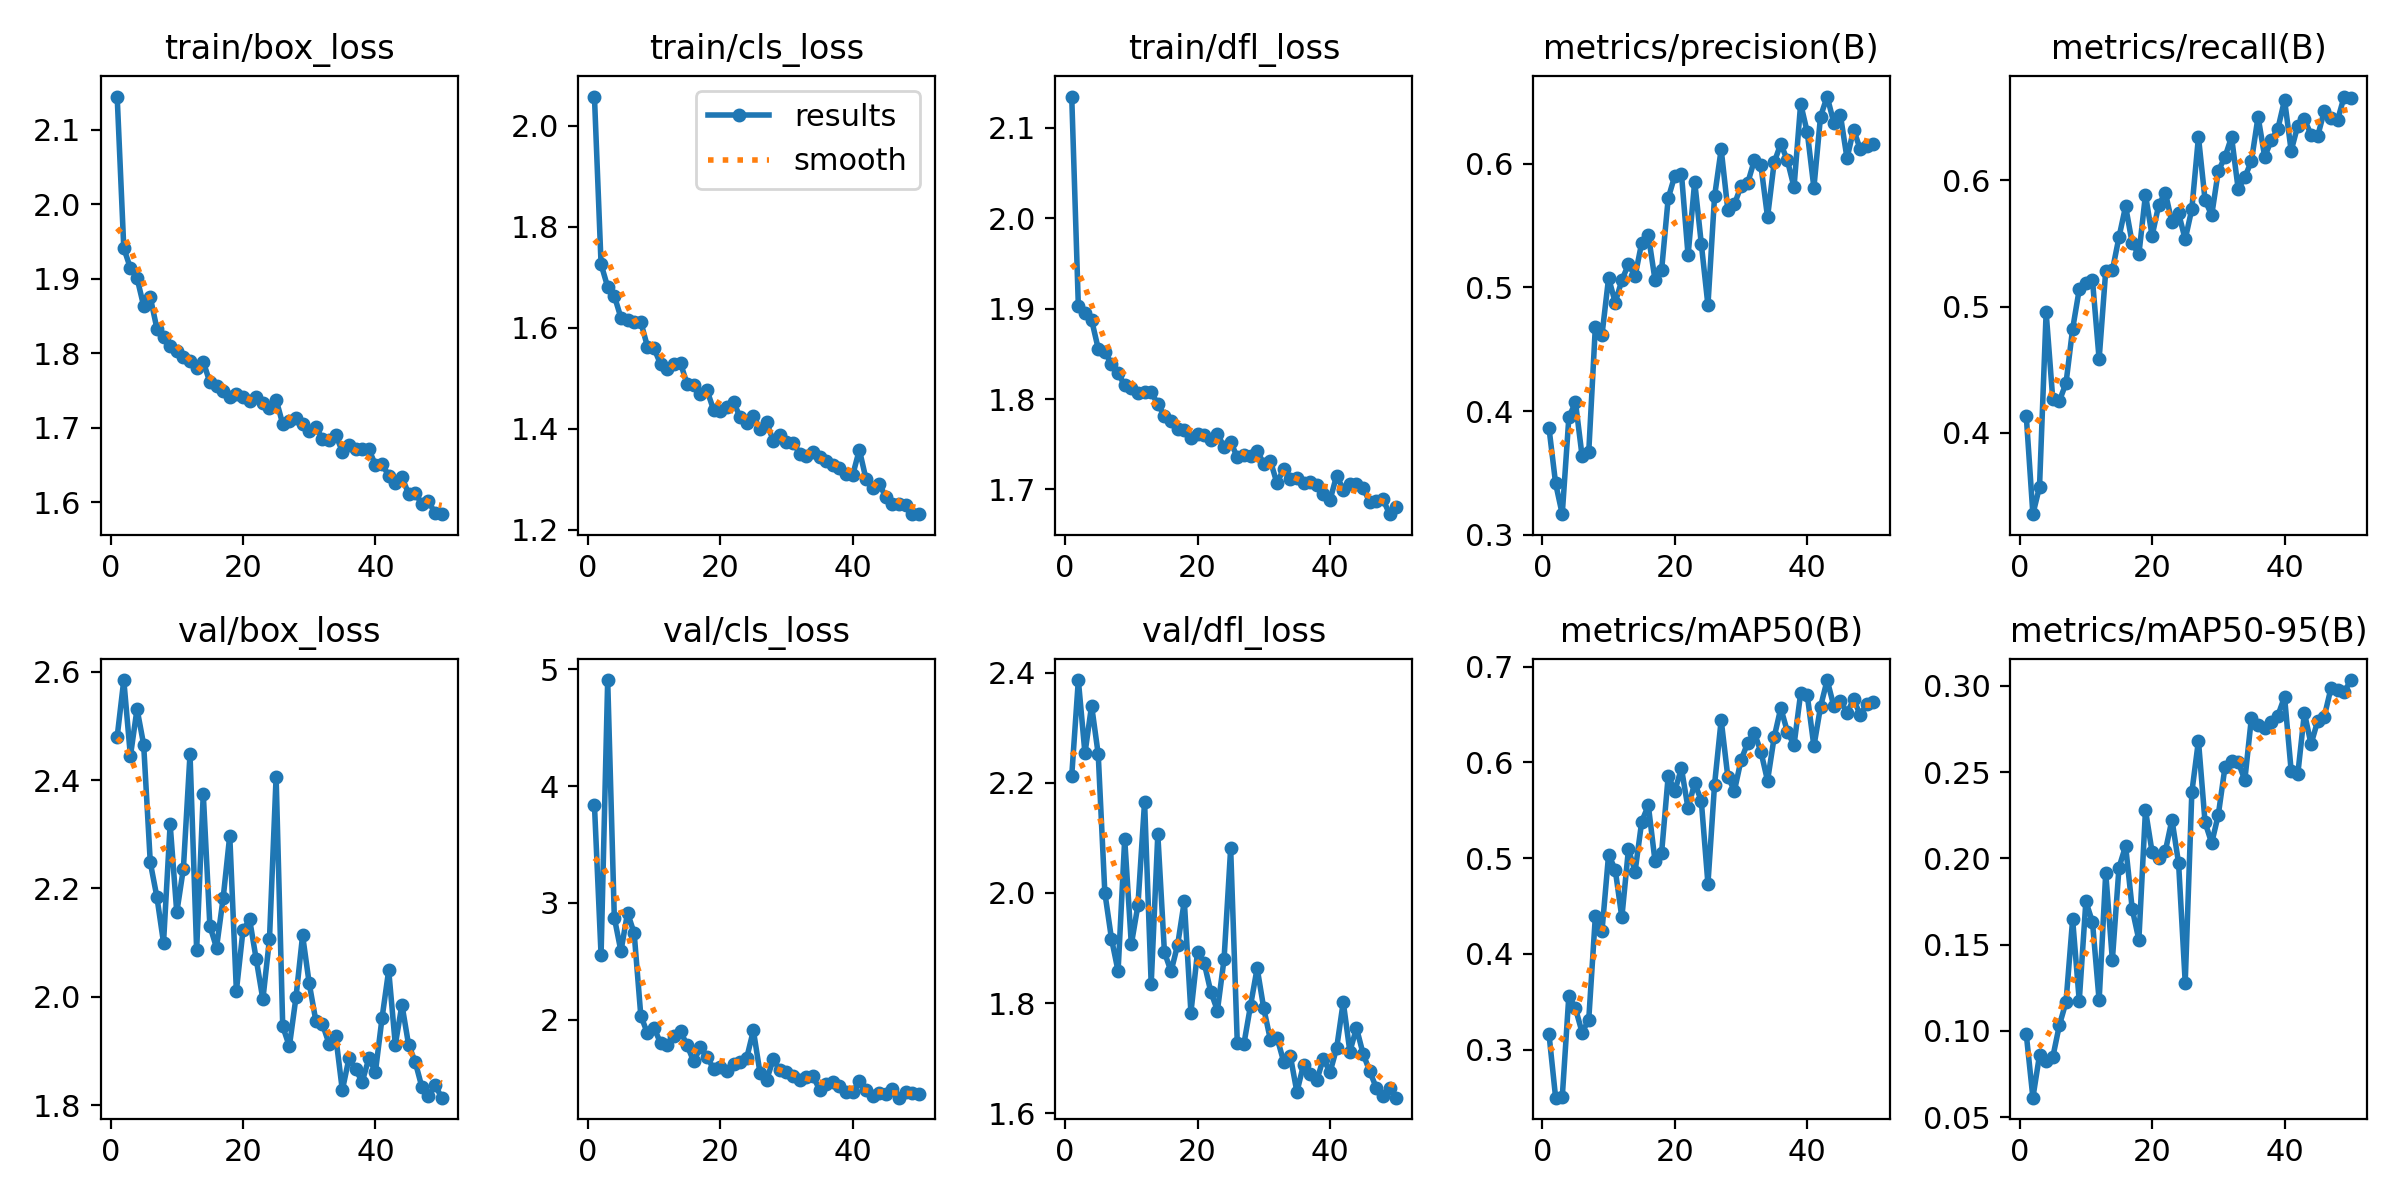


🎯 Normalized Confusion Matrix:


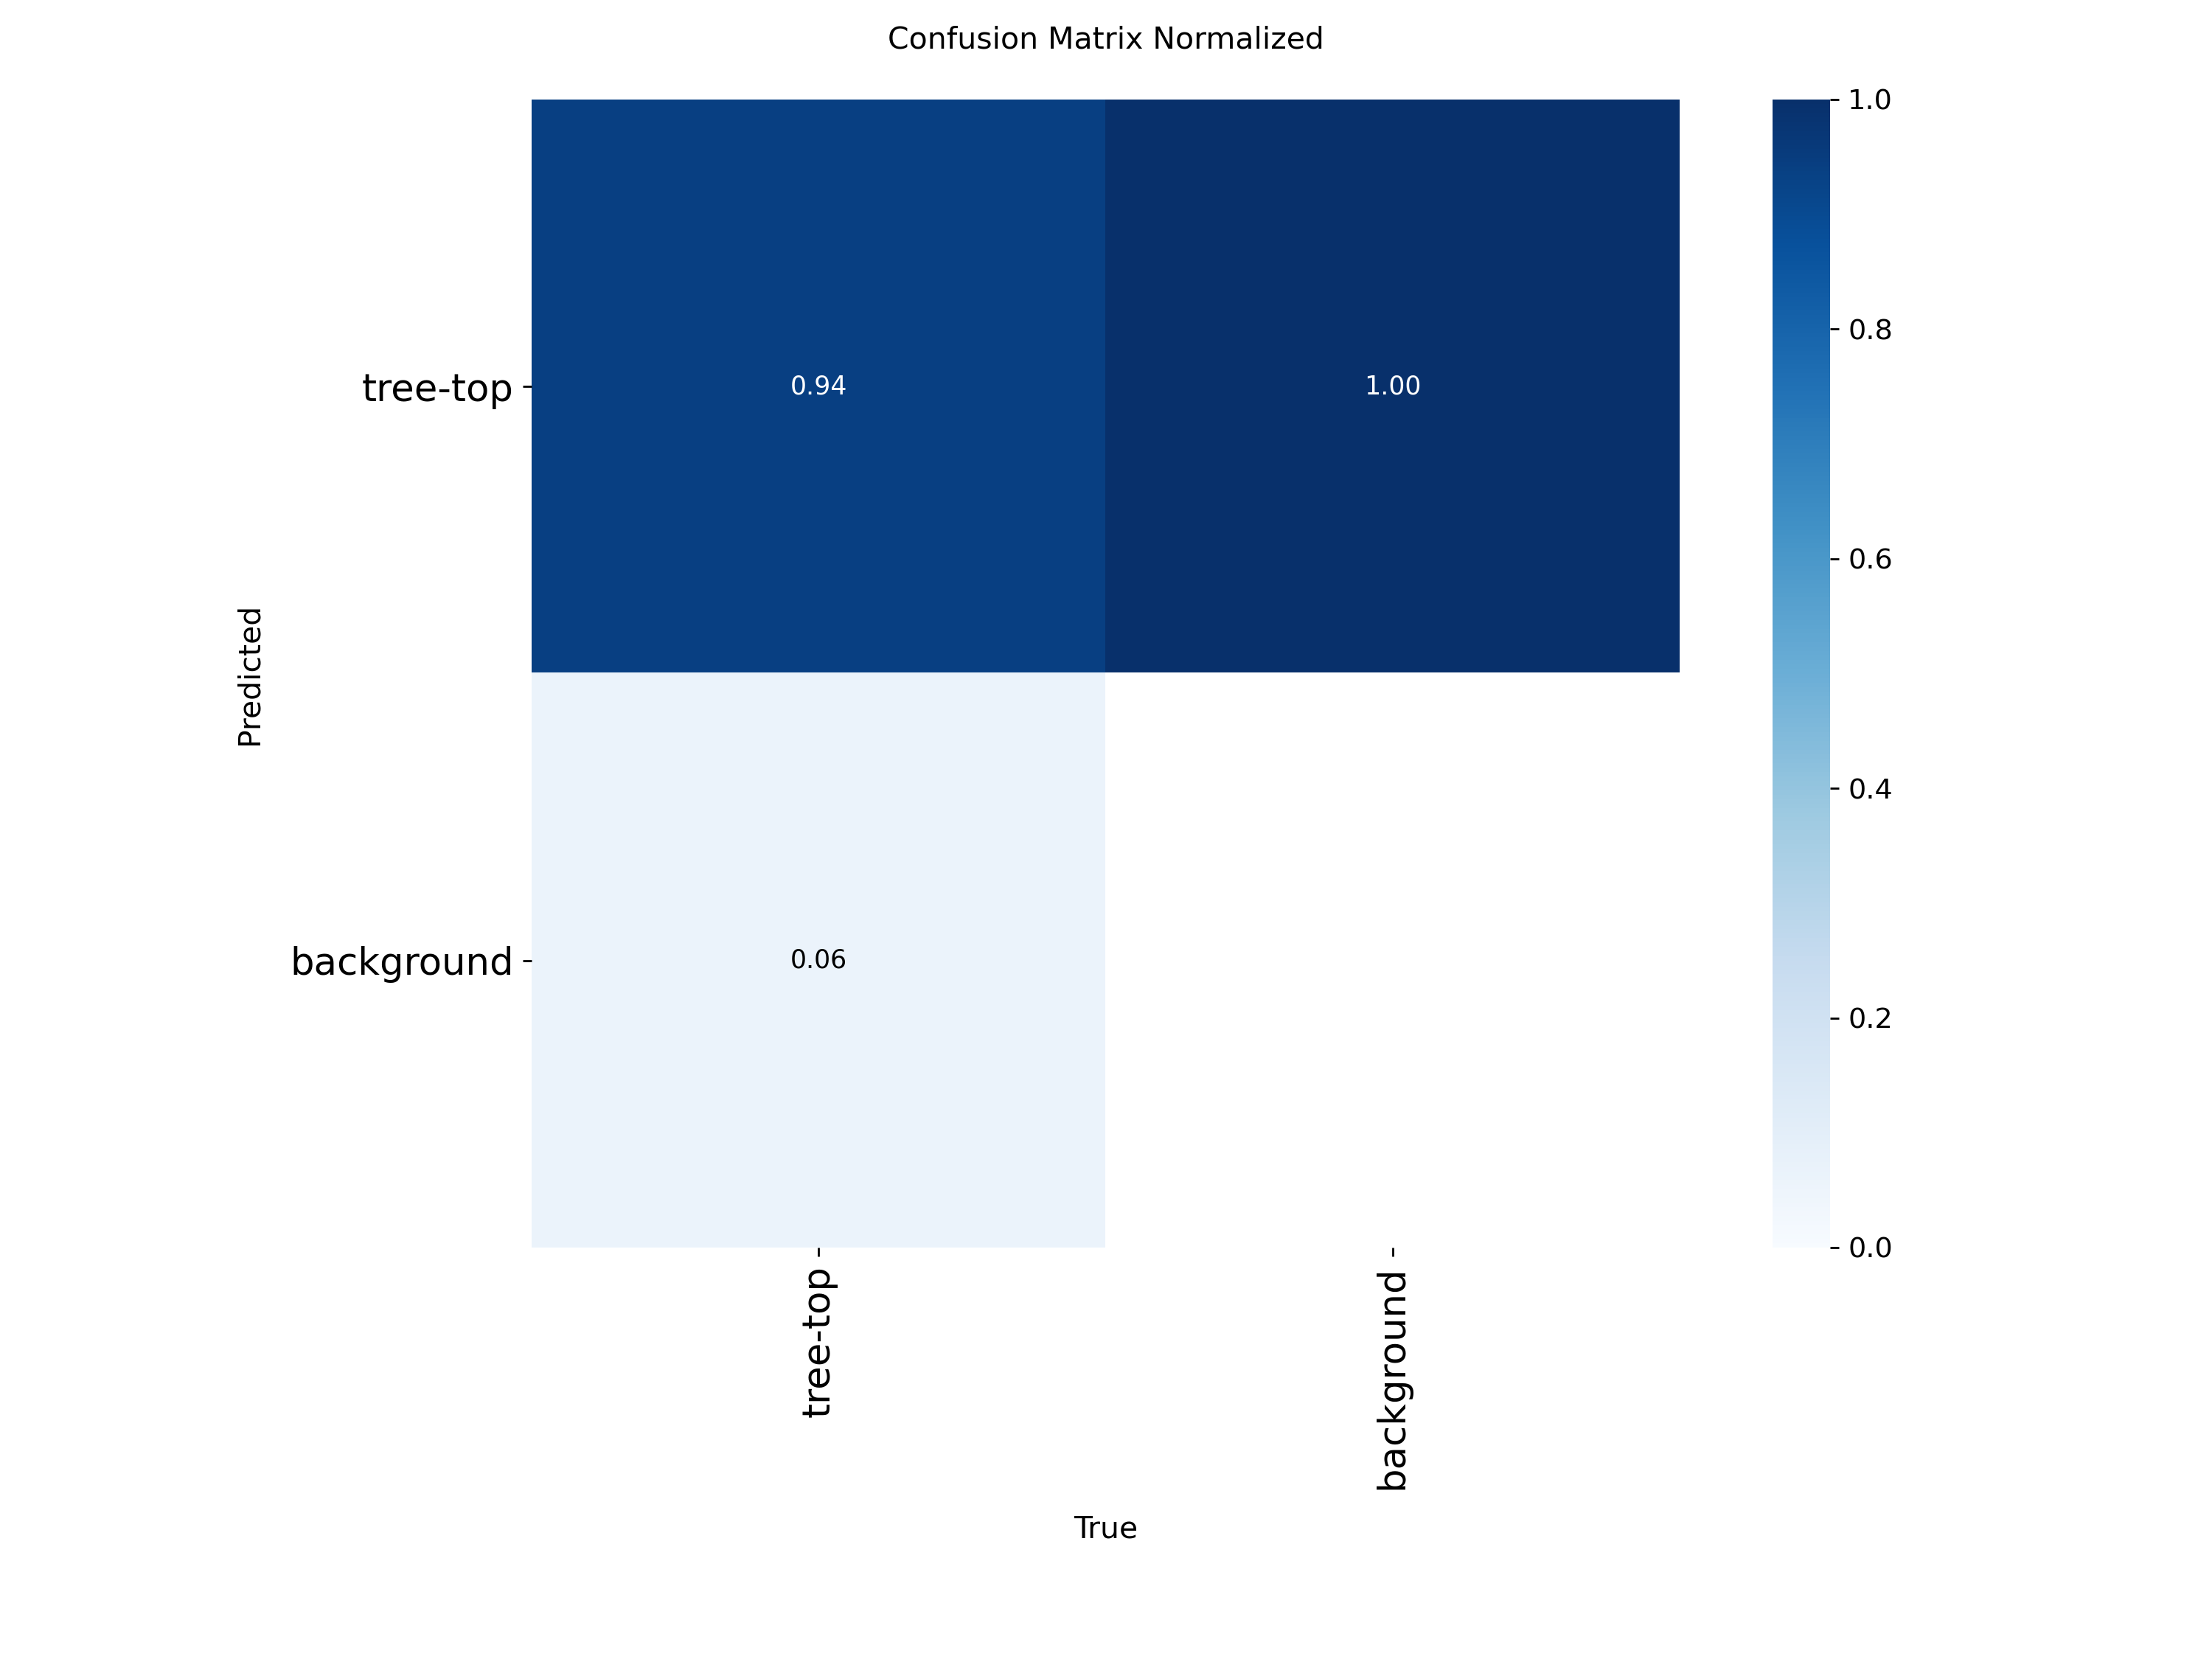


🌲 Drone Aerial Tree Crown Detections (Validation Batch 0):


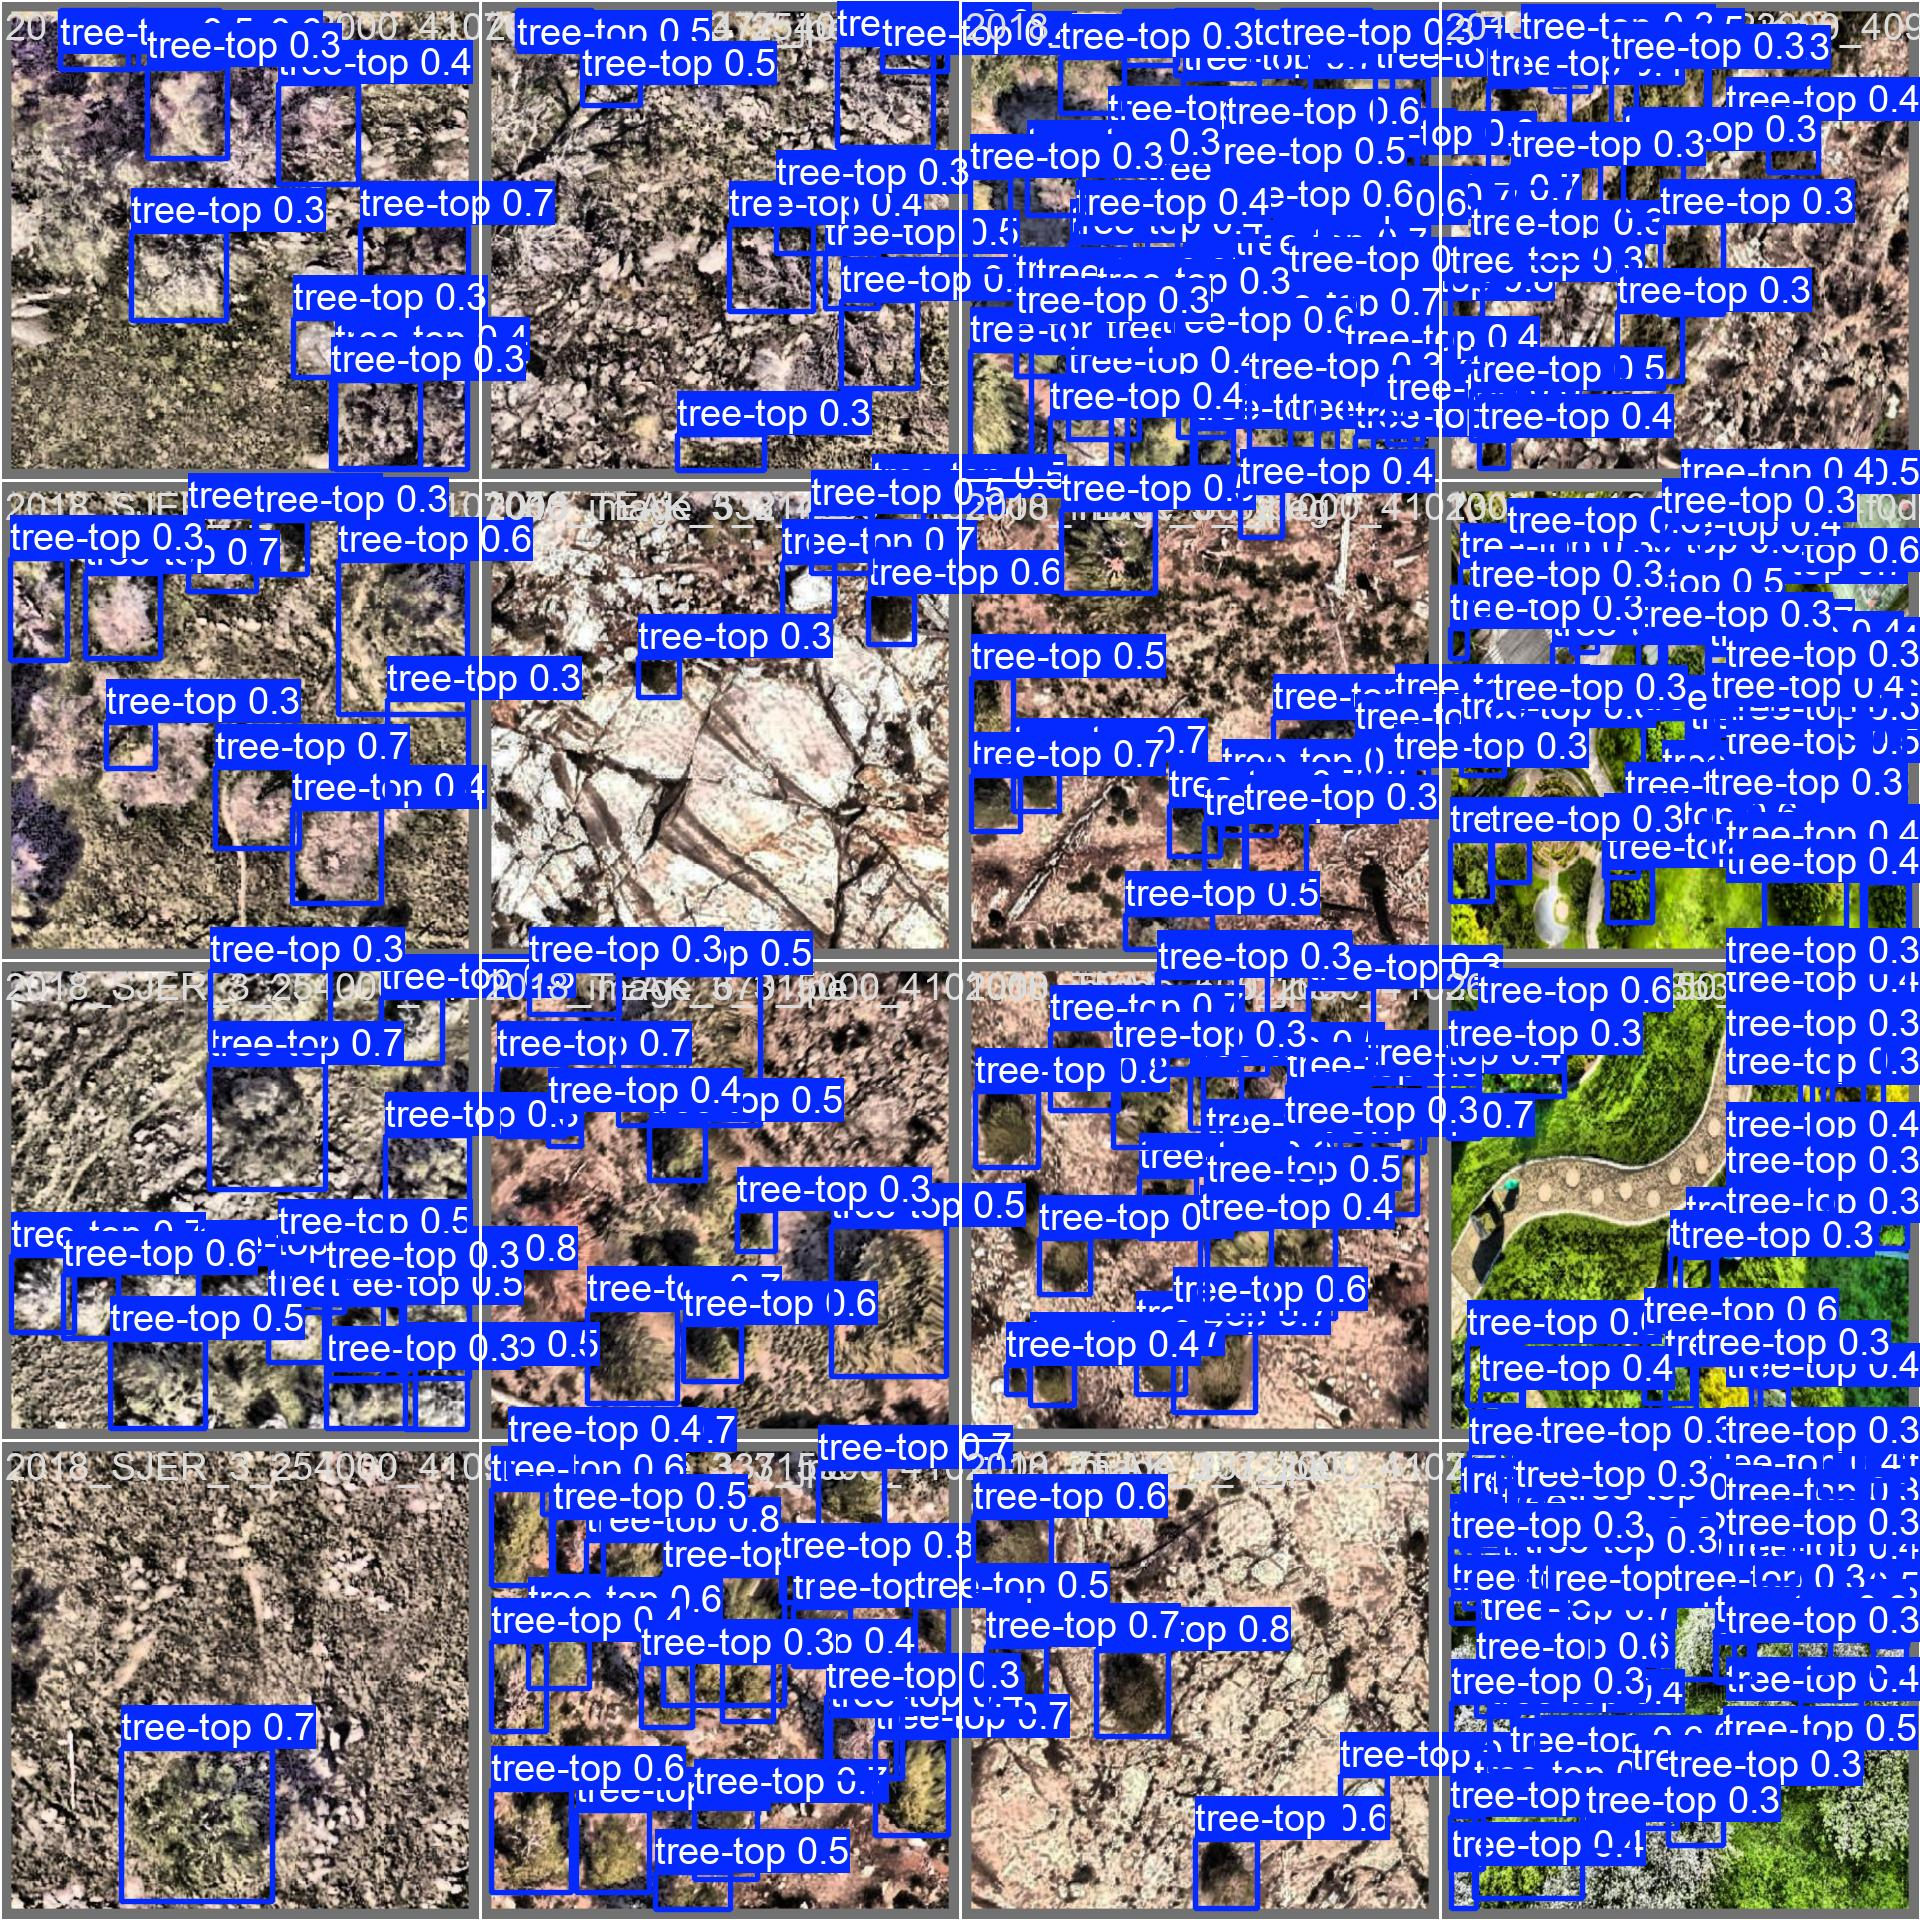

In [5]:
# Cell 5: Visual Validation & Metrics Display
import os
import glob
from IPython.display import Image, display

RUN_DIR = "/content/drive/MyDrive/TreeSense_AI_Training_main/checkpoints/yolo11_treesense_v6"

print("=" * 60)
print("📊 TRAINING PERFORMANCE CURVES & PREDICTIONS")
print("=" * 60)

# Display Loss & mAP Curves
results_png = f"{RUN_DIR}/results.png"
if os.path.exists(results_png):
    print("📈 Training & Validation Curves:")
    display(Image(filename=results_png, width=900))

# Display Confusion Matrix
cm_png = f"{RUN_DIR}/confusion_matrix_normalized.png"
if os.path.exists(cm_png):
    print("\n🎯 Normalized Confusion Matrix:")
    display(Image(filename=cm_png, width=600))

# Display Sample Validation Predictions
val_preds = glob.glob(f"{RUN_DIR}/val_batch*_pred.jpg")
if val_preds:
    print("\n🌲 Drone Aerial Tree Crown Detections (Validation Batch 0):")
    display(Image(filename=val_preds[0], width=900))

In [6]:
# Cell 6: Export to High-Speed ONNX FP16
from ultralytics import YOLO
import os
import shutil

BEST_PT = "/content/drive/MyDrive/TreeSense_AI_Training_main/checkpoints/yolo11_treesense_v6/weights/best.pt"
EXPORTS_DIR = "/content/drive/MyDrive/TreeSense_AI_Training_main/exports"
os.makedirs(EXPORTS_DIR, exist_ok=True)

print("📦 Exporting YOLOv11m to ONNX FP16 (with dynamic axes for SAHI)...")
model = YOLO(BEST_PT)

onnx_path = model.export(
    format="onnx",
    half=True,       # FP16 acceleration
    dynamic=True,    # Dynamic shape for sliced tiling
    opset=17
)

# Copy both best.pt and best.onnx to exports folder in Drive
shutil.copy(BEST_PT, f"{EXPORTS_DIR}/best.pt")
shutil.copy(onnx_path, f"{EXPORTS_DIR}/best.onnx")

print("=" * 60)
print(f"✅ PyTorch Model : {EXPORTS_DIR}/best.pt")
print(f"✅ ONNX Model    : {EXPORTS_DIR}/best.onnx")
print("=" * 60)
print("👉 Ready for Cell 7 (Download Package)!")

📦 Exporting YOLOv11m to ONNX FP16 (with dynamic axes for SAHI)...
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/TreeSense_AI_Training_main/checkpoints/yolo11_treesense_v6/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (38.6 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 10 packages in 249ms
Prepared 2 packages in 30ms
Installed 2 packages in 5ms
 + colorama==0.4.6
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requiremen

In [7]:
# Cell 7: Package and Download Release ZIP
import shutil
import os
from google.colab import files

ZIP_DIR = "/content/TreeSense_YOLO11_Release"
ZIP_FILE = "/content/TreeSense_YOLO11_Release.zip"
RUN_DIR = "/content/drive/MyDrive/TreeSense_AI_Training_main/checkpoints/yolo11_treesense_v6"
EXPORTS_DIR = "/content/drive/MyDrive/TreeSense_AI_Training_main/exports"

os.makedirs(ZIP_DIR, exist_ok=True)

# 1. Copy Models
shutil.copy(f"{EXPORTS_DIR}/best.pt", os.path.join(ZIP_DIR, "best.pt"))
shutil.copy(f"{EXPORTS_DIR}/best.onnx", os.path.join(ZIP_DIR, "best.onnx"))

# 2. Copy Evaluation Charts
for chart in ["results.png", "BoxPR_curve.png", "confusion_matrix.png", "val_batch0_pred.jpg"]:
    src = f"{RUN_DIR}/{chart}"
    if os.path.exists(src):
        shutil.copy(src, ZIP_DIR)

# 3. Create Zip Archive
shutil.make_archive(ZIP_DIR, "zip", ZIP_DIR)

print("🚀 Starting download to your computer...")
files.download(ZIP_FILE)

🚀 Starting download to your computer...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>